In [1]:
import os
import logging
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['pdf.fonttype'] = 42
import seaborn as sns
from scipy.stats import mannwhitneyu
from Bio.PDB.MMCIFParser import MMCIFParser
from Bio.PDB import NeighborSearch
warnings.filterwarnings("ignore")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

In [2]:
# non-covalent contacts per model (Protein Contacts Atlas categories, Kayikci et al. 2018 NSMB),
# heavy atoms only (no H in AF3 models):
#   vdW: any heavy-atom pair <= 4.5 A (superset, includes the other two)
#   H-bond proxy: N/O - N/O <= 3.5 A
#   salt bridge: Lys/Arg/His cation vs Asp/Glu carboxylate or DNA phosphate O <= 4.0 A
# protein-DNA contacts split into base (direct readout) vs backbone (sugar-phosphate)
dt = pd.read_csv("../data/tangermeme_hard_syntax_top_and_worst_motif_examples_n100_rho0.6.csv", dtype={"motif_combination": str})
manifest = dt[["motif_combination", "background_idx", "class", "TF1", "TF2"]].rename(columns={"motif_combination": "combo"})
manifest["group"] = manifest["TF1"] + "_" + manifest["TF2"] + "_" + manifest["combo"]
manifest["name"] = manifest["group"] + "_" + manifest["class"] + "_bg" + manifest["background_idx"].astype(str)
manifest["model_path"] = "../af3_screen_n100_rho0.6/outputs_inference/" + manifest["name"] + "_model.cif"
manifest["exists"] = manifest["model_path"].apply(os.path.exists)
manifest["exists"].value_counts()

exists
True    6400
Name: count, dtype: int64

In [3]:
DNA_BACKBONE = {"P", "OP1", "OP2", "OP3", "O5'", "C5'", "C4'", "O4'", "C3'", "O3'", "C2'", "C1'"}
POS_ATOMS = {("LYS", "NZ"), ("ARG", "NH1"), ("ARG", "NH2"), ("ARG", "NE"), ("HIS", "ND1"), ("HIS", "NE2")}
NEG_ATOMS = {("ASP", "OD1"), ("ASP", "OD2"), ("GLU", "OE1"), ("GLU", "OE2")}
PHOSPHATE_O = {"OP1", "OP2", "OP3"}
parser = MMCIFParser(QUIET=True)

def yy_contacts(model):
    """Count contacts per (chain pair, category, DNA region) for one model."""
    atoms = list(model.get_atoms())
    counts = {}
    for a1, a2 in NeighborSearch(atoms).search_all(4.5, level="A"):
        c1, c2 = a1.get_parent().get_parent().id, a2.get_parent().get_parent().id
        g1 = "DNA" if c1 in ("C", "D") else c1
        g2 = "DNA" if c2 in ("C", "D") else c2
        if g1 == g2:  # same chain, or DNA-DNA
            continue
        key = tuple(sorted([g1, g2]))
        d = a1 - a2
        r1, n1, e1 = a1.get_parent().resname, a1.get_name(), a1.element
        r2, n2, e2 = a2.get_parent().resname, a2.get_name(), a2.element
        region = None
        if "DNA" in key:
            dna_atom = n1 if g1 == "DNA" else n2
            region = "backbone" if dna_atom in DNA_BACKBONE else "base"
        cats = ["vdw"]
        if d <= 3.5 and e1 in ("N", "O") and e2 in ("N", "O"):
            cats.append("hbond")
        pos = (r1, n1) in POS_ATOMS or (r2, n2) in POS_ATOMS
        neg = (r1, n1) in NEG_ATOMS or (r2, n2) in NEG_ATOMS or n1 in PHOSPHATE_O or n2 in PHOSPHATE_O
        if d <= 4.0 and pos and neg:
            cats.append("saltbridge")
        for cat in cats:
            counts[(key, cat, region)] = counts.get((key, cat, region), 0) + 1
    return counts

In [4]:
# ~40 min for all models, resume from the checkpoint
checkpoint = "../results/cache/protein_dna_contacts_checkpoint.csv"
records = pd.read_csv(checkpoint).to_dict("records") if os.path.exists(checkpoint) else []
todo = manifest[manifest["exists"] & ~manifest["name"].isin({r["name"] for r in records})]
print(f"{len(records)} done, {len(todo)} to do")

for i, (_, row) in enumerate(todo.iterrows()):
    counts = yy_contacts(parser.get_structure(row["name"], row["model_path"])[0])
    rec = {"name": row["name"], "group": row["group"], "combo": row["combo"],
           "background_idx": row["background_idx"], "class": row["class"],
           "TF1": row["TF1"], "TF2": row["TF2"], "pair": row["TF1"] + "-" + row["TF2"]}
    for cat in ["vdw", "hbond", "saltbridge"]:
        rec[f"PP_{cat}"] = counts.get((("A", "B"), cat, None), 0)
        for chain, tf in [("A", "TF1"), ("B", "TF2")]:
            for region in ["base", "backbone"]:
                rec[f"{tf}_DNA_{cat}_{region}"] = counts.get(((chain, "DNA"), cat, region), 0)
    records.append(rec)
    if (i + 1) % 500 == 0 or i + 1 == len(todo):
        pd.DataFrame(records).to_csv(checkpoint, index=False)

6400 done, 0 to do


In [5]:
results = pd.DataFrame(records)
results["class"] = pd.Categorical(results["class"], categories=["high", "low"], ordered=True)

# fraction of TF-DNA vdW contacts that touch bases (direct readout)
for tf in ["TF1", "TF2"]:
    for cat in ["vdw", "hbond"]:
        results[f"{tf}_DNA_{cat}_total"] = results[f"{tf}_DNA_{cat}_base"] + results[f"{tf}_DNA_{cat}_backbone"]
    results[f"{tf}_DNA_vdw_frac_base"] = results[f"{tf}_DNA_vdw_base"] / results[f"{tf}_DNA_vdw_total"].replace(0, np.nan)

# TF1/TF2 is not a fixed structural role (which TF's motif sits 5' flips between groups),
# so sum TF1 + TF2 per model for the DNA contacts
for cat in ["vdw", "hbond"]:
    for region in ["base", "backbone"]:
        results[f"DNA_{cat}_{region}_total"] = results[f"TF1_DNA_{cat}_{region}"] + results[f"TF2_DNA_{cat}_{region}"]
results["DNA_saltbridge_backbone_total"] = results["TF1_DNA_saltbridge_backbone"] + results["TF2_DNA_saltbridge_backbone"]
results["DNA_vdw_frac_base_total"] = results["DNA_vdw_base_total"] / (
    results["DNA_vdw_base_total"] + results["DNA_vdw_backbone_total"]).replace(0, np.nan)

results.to_csv("../results/tables/protein_dna_contacts_high_vs_low.csv", index=False)
results.head()

,name,group,combo,background_idx,class,TF1,TF2,pair,PP_vdw,TF1_DNA_vdw_base,...,TF1_DNA_vdw_frac_base,TF2_DNA_vdw_total,TF2_DNA_hbond_total,TF2_DNA_vdw_frac_base,DNA_vdw_base_total,DNA_vdw_backbone_total,DNA_hbond_base_total,DNA_hbond_backbone_total,DNA_saltbridge_backbone_total,DNA_vdw_frac_base_total
0,BCL11B_ETS1_14_64_high_bg0,BCL11B_ETS1_14_64,14_64,0,high,BCL11B,ETS1,BCL11B-ETS1,864,153,...,0.531250,254,19,0.397638,254,288,15,19,11,0.468635
1,BCL11B_GABPA_14_64_high_bg0,BCL11B_GABPA_14_64,14_64,0,high,BCL11B,GABPA,BCL11B-GABPA,791,184,...,0.488064,316,24,0.329114,288,405,21,33,19,0.415584
2,BCL11B_IKZF1_14_64_high_bg0,BCL11B_IKZF1_14_64,14_64,0,high,BCL11B,IKZF1,BCL11B-IKZF1,293,120,...,0.309278,349,36,0.260745,211,526,24,61,31,0.286296
3,RUNX1_ETS1_14_64_high_bg0,RUNX1_ETS1_14_64,14_64,0,high,RUNX1,ETS1,RUNX1-ETS1,282,115,...,0.479167,293,24,0.361775,221,312,22,21,12,0.414634
4,RUNX1_GABPA_14_64_high_bg0,RUNX1_GABPA_14_64,14_64,0,high,RUNX1,GABPA,RUNX1-GABPA,286,125,...,0.506073,380,26,0.331579,251,376,25,26,15,0.400319


In [6]:
metrics = ["PP_vdw", "PP_hbond", "PP_saltbridge",
           "DNA_vdw_base_total", "DNA_vdw_backbone_total", "DNA_hbond_base_total", "DNA_hbond_backbone_total",
           "DNA_saltbridge_backbone_total", "DNA_vdw_frac_base_total"]
rows = []
for col in metrics:
    high = results[results["class"] == "high"][col].dropna()
    low = results[results["class"] == "low"][col].dropna()
    stat, p_value = mannwhitneyu(high, low, alternative="two-sided")
    rows.append({"metric": col, "mean_high": high.mean(), "mean_low": low.mean(),
                 "diff": high.mean() - low.mean(), "mannwhitney_p": p_value,
                 "direction": "high > low" if high.mean() > low.mean() else "low > high",
                 "significant_p<0.05": p_value < 0.05})
summary_df = pd.DataFrame(rows).round(4)
summary_df.to_csv("../results/tables/protein_dna_contacts_summary_table.csv", index=False)
summary_df

,metric,mean_high,mean_low,diff,mannwhitney_p,direction,significant_p<0.05
0,PP_vdw,269.9231,220.7528,49.1703,0.0000,high > low,True
1,PP_hbond,13.3275,10.5897,2.7378,0.0000,high > low,True
2,PP_saltbridge,4.9828,4.0066,0.9762,0.0000,high > low,True
3,DNA_vdw_base_total,201.8100,201.0181,0.7919,0.0000,high > low,True
4,DNA_vdw_backbone_total,390.5231,375.9559,14.5672,0.0000,high > low,True
5,DNA_hbond_base_total,19.3103,19.4669,-0.1566,0.0437,low > high,True
6,DNA_hbond_backbone_total,29.7834,29.3872,0.3963,0.3106,high > low,False
7,DNA_saltbridge_backbone_total,16.4728,16.4359,0.0369,0.0941,high > low,False
8,DNA_vdw_frac_base_total,0.3324,0.3390,-0.0066,0.0157,low > high,True


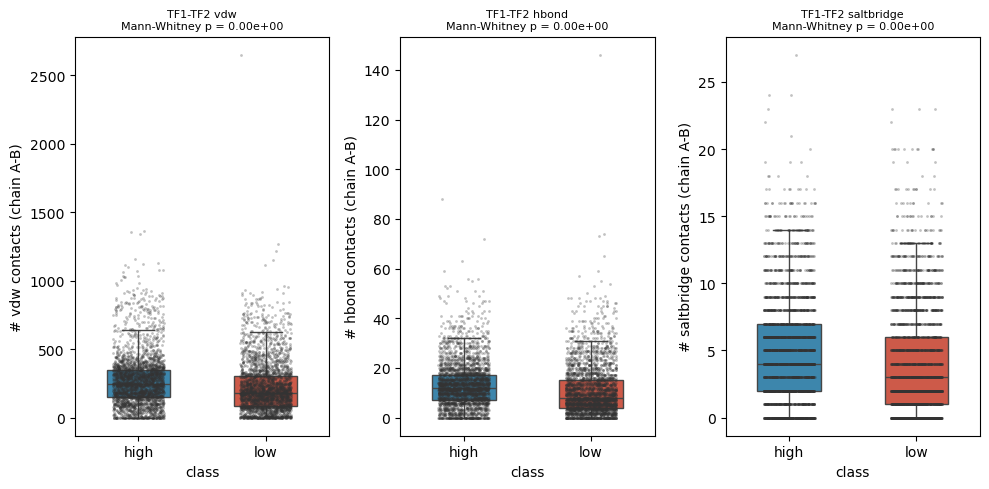

In [7]:
palette = {"high": "#2b8cbe", "low": "#e34a33"}

def yy_boxstrip(df, y, ax):
    sns.boxplot(data=df, x="class", y=y, hue="class", order=["high", "low"], palette=palette,
                width=0.5, fliersize=0, legend=False, ax=ax)
    sns.stripplot(data=df, x="class", y=y, order=["high", "low"], color="0.2", size=2, jitter=0.2, alpha=0.3, ax=ax)

fig, axes = plt.subplots(1, 3, figsize=(10, 5))
for ax, cat in zip(axes, ["vdw", "hbond", "saltbridge"]):
    yy_boxstrip(results, f"PP_{cat}", ax)
    p_value = summary_df.set_index("metric").loc[f"PP_{cat}", "mannwhitney_p"]
    ax.set_title(f"TF1-TF2 {cat}\nMann-Whitney p = {p_value:.2e}", fontsize=8)
    ax.set_ylabel(f"# {cat} contacts (chain A-B)")
plt.tight_layout()
plt.savefig("../results/figures/protein_protein_contacts_high_vs_low.pdf", bbox_inches='tight')
plt.show()
plt.close()

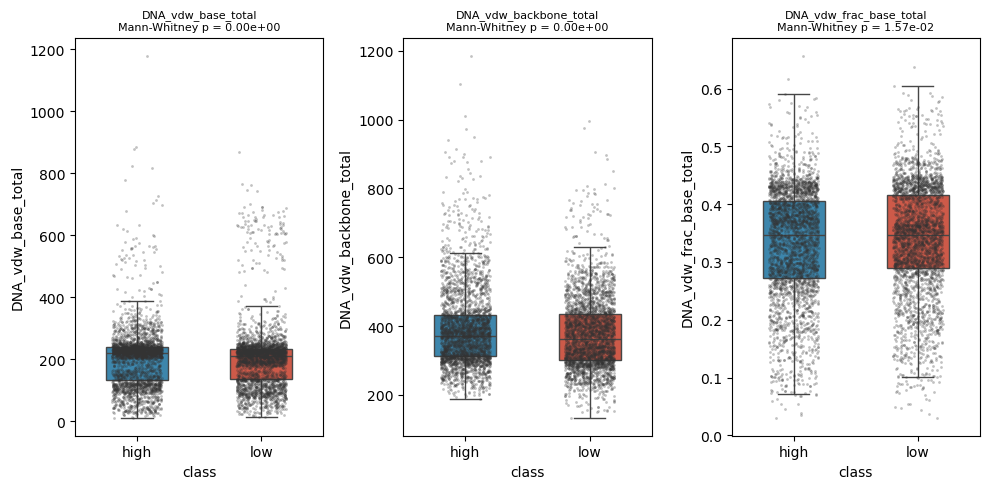

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(10, 5))
for ax, col in zip(axes, ["DNA_vdw_base_total", "DNA_vdw_backbone_total", "DNA_vdw_frac_base_total"]):
    yy_boxstrip(results, col, ax)
    p_value = summary_df.set_index("metric").loc[col, "mannwhitney_p"]
    ax.set_title(f"{col}\nMann-Whitney p = {p_value:.2e}", fontsize=8)
    ax.set_ylabel(col)
plt.tight_layout()
plt.savefig("../results/figures/protein_dna_contacts_total_base_vs_backbone.pdf", bbox_inches='tight')
plt.show()
plt.close()

In [9]:
# one table per model: protein-DNA BSA/ipTM (notebook 1) + contacts
bsa = pd.read_csv("../results/tables/protein_dna_bsa_high_vs_low.csv")
contacts = pd.read_csv("../results/tables/protein_dna_contacts_high_vs_low.csv")
meta = ["group", "combo", "background_idx", "class", "TF1", "TF2", "pair"]
merged = bsa.merge(contacts.drop(columns=meta), on="name", how="inner", validate="1:1")
merged.to_csv("../results/tables/protein_dna_bsa_contacts_high_vs_low.csv", index=False)
merged.shape

(6400, 44)

In [10]:
# master table (one row per model): TF1-TF2 BSA + ipTM (notebook 0), protein-DNA BSA + ipTM (notebook 1), all contacts (no PAE)
ppi = pd.read_csv("../results/tables/bsa_n100_rho0.6_high_vs_low.csv")
ppi = ppi.rename(columns={"SASA_complex": "SASA_TF1_TF2_complex", "BSA": "BSA_TF1_TF2", "iptm_AB": "iptm_TF1_TF2"})
master = ppi.merge(merged.drop(columns=meta + ["SASA_TF1", "SASA_TF2"]), on="name", how="inner", validate="1:1")
master.to_csv("../results/tables/master_bsa_iptm_contacts_high_vs_low.csv", index=False)
master.shape

(6400, 47)